## Focus on metrics that assess the quality of the inherent groupings found within the data. Here's a breakdown of commonly used metrics and a Python example:

# Key Metrics:

## Silhouette Coefficient
Measures how similar an object is to its own cluster compared to other clusters.
Ranges from -1 to 1:
* 1: Well-separated clusters.
* 0: Overlapping clusters.
* -1: Points likely assigned to the wrong cluster.

## Calinski-Harabasz Index
Calculates the ratio of between-cluster variance to within-cluster variance.
Higher values indicate better-defined clusters.

## Davies-Bouldin Index
Measures the average similarity between each cluster and its most similar cluster.
Lower values indicate better clustering (0 is the minimum).

## Inertia (for K-Means)
Calculates the sum of squared distances of samples to their closest cluster center.
Lower inertia indicates denser clusters - but it **always** decreases as k grows, so it cannot pick k on its own.

## Adjusted Rand Index (ARI)
If ground truth labels are available, the ARI measures the similarity between true labels and predicted cluster labels, adjusting for chance.
Ranges from -1 to 1, with 1 being a perfect match and ~0 being random labeling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
)
from sklearn.datasets import make_blobs

# Generate sample data (y = true group, normally unknown in unsupervised learning)
X, y = make_blobs(n_samples=300, centers=4, random_state=42)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
labels = kmeans.fit_predict(X)

print(f"Silhouette Coefficient: {silhouette_score(X, labels):.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz_score(X, labels):.1f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X, labels):.4f}")
print(f"K-Means Inertia: {kmeans.inertia_:.1f}")

# Only possible because this synthetic data comes with true labels
print(f"Adjusted Rand Index: {adjusted_rand_score(y, labels):.4f}")

Silhouette Coefficient: 0.7916
Calinski-Harabasz Index: 3386.4
Davies-Bouldin Index: 0.2905
K-Means Inertia: 564.9
Adjusted Rand Index: 0.9911


## Using the metrics to choose the number of clusters
In practice the right k is unknown. Fit several values and compare: look for the silhouette peak,
the Davies-Bouldin minimum, and the "elbow" where inertia stops dropping sharply.

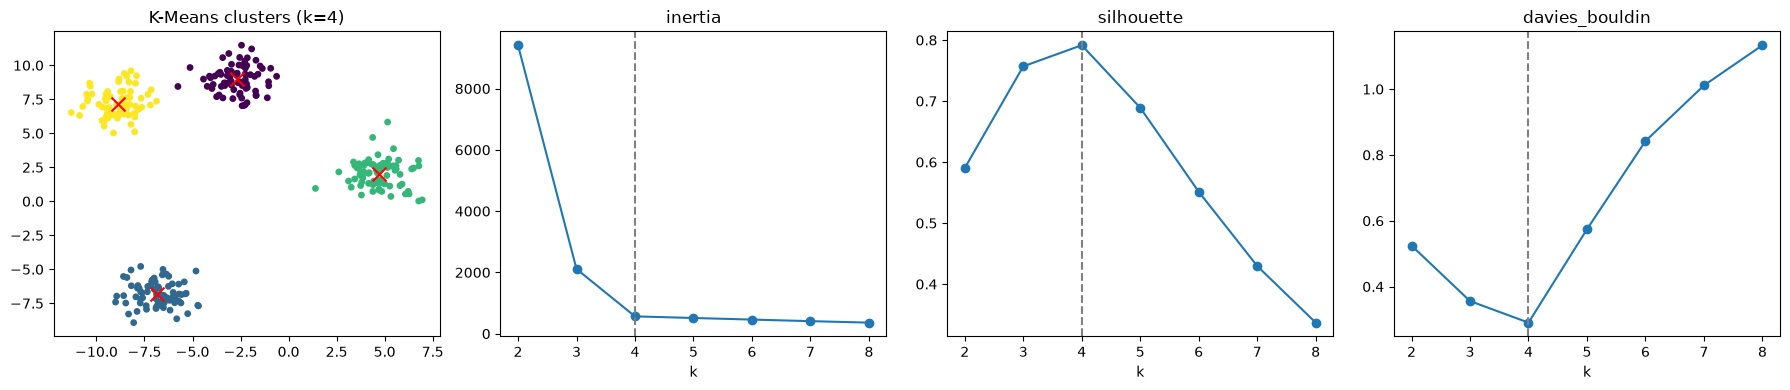

Best k by silhouette: 4
Best k by Davies-Bouldin: 4


In [2]:
ks = range(2, 9)
results = {'inertia': [], 'silhouette': [], 'davies_bouldin': []}
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    results['inertia'].append(km.inertia_)
    results['silhouette'].append(silhouette_score(X, km.labels_))
    results['davies_bouldin'].append(davies_bouldin_score(X, km.labels_))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].scatter(X[:, 0], X[:, 1], c=labels, s=15, cmap='viridis')
axes[0].scatter(*kmeans.cluster_centers_.T, c='red', marker='x', s=100)
axes[0].set_title('K-Means clusters (k=4)')
for ax, (name, values) in zip(axes[1:], results.items()):
    ax.plot(list(ks), values, 'o-')
    ax.axvline(4, color='gray', linestyle='--')
    ax.set_xlabel('k')
    ax.set_title(name)
plt.tight_layout()
plt.show()

print(f"Best k by silhouette: {ks[int(np.argmax(results['silhouette']))]}")
print(f"Best k by Davies-Bouldin: {ks[int(np.argmin(results['davies_bouldin']))]}")